# **LightGBM**

장점
- 더빠른 학습과 예측 수행 시간
- 더작은 메모리사용량
- 카테고리형 피처의 자동 변환과 최적 분할（원-핫 인코딩 등을 사용하지 않= 카테고리형 피처를 최적으로 변환하고 이에 따른 노드 분할 수행）

-> LightGBM은 일반 GBM 계열의 트리 분할 방법과 다르게 리프 중심 트리 분할(Leaf Wise) 방식을 사용
- 기존의 대부분 트리 기반 알고리즘은 트리의 깊이를 효과적으로 줄이기 위한 균형 트리 분할
(Level Wise) 방식을 사용, 즉, 최대한 균형 잡힌 트리를 유지하면서 분할하기 때문에 트리의 깊
이가 최소화될 수 있다. 이렇게 균형 잡힌 트리를 생성하는 이유는 오버피팅에 보다 더 강한 구조
를 가질 수 있다고 알려져 있기 때문이다

-> 균형을 맞추기 위한 시간이 필요하다는 상대적인
단점도 있다

- LightGBM의 파이썬 패키지명: 'lightgbm'
- 사이킷런 래퍼 LightGBM 클래스는 분류를 위한 LGBMClassifier 클래스와 회귀를 위한
LGBMRegressor 클래스

# LightGBM 설치

In [1]:
pip install scikit-learn==1.2.2

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 56.7 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (pyproject.toml) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> scikit-learn

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


In [2]:
pip install xgboost ==1.7.6


ERROR: Invalid requirement: '==1.7.6': Expected package name at the start of dependency specifier
    ==1.7.6
    ^


In [3]:
pip install lightgbm==3.3.2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 45.5 MB/s  0:00:00
  Attempting uninstall: lightgbm
    Found existing installation: lightgbm 4.6.0
    Uninstalling lightgbm-4.6.0:
      Successfully uninstalled lightgbm-4.6.0


In [4]:
import lightgbm
from lightgbm import LGBMClassifier

# LightGBM 하이퍼 파라미터

<주요 파라미터>
- num_iteratioins[default=100]: 반복 수행하려는 트리의 개수 지정.
  - 크게 지정할 수록 예측 성능이 높아질 수 있으나, 너무 크게 지정하면 오히려 과적합으로 성능ㅇ 저하될 수 있다
  -사이킷런 GBM과 XGBoost의 사이킷런 호환
클래스의 n_estimators와 같은 파라미터로 LightGBM의 사이킷런 호환 클래스에서는 n_estimators로 이름 변경 가능
- learning_rate[default=0.1]: 0에서 1 사이의 값을 지정하며 부스팅 스텝을 반복적으로 수행할 /ㄷ/ㅐ 업데이트되는 학습률 값
  - 일반적으로 n_estimators를 크게 하고 learning_rate를 작게 해서 예측 성능을 향상시킬 수 있드나 마찬가지로 과적합 이슈와 학습 시간이 길어지는 부정적인 영향도 고려해야 한다.
- max_depth[default=-1]: 트리 기반 알고리즘의 max_depth와 같음. 0보다 작은 값을 지정하면 깊이에 제한이 없다.
  - 지금까지 소개한 Depth wise 방식의 트리와 다르게 LightGBM은 Leaf wise 기반이므로 깊이가 상대적으로 더 깊다
- min_data_in_leaf[default=20]: 결정 트리의 min_samples_leaf와 같은 파라미터. 하지만 사이킷런 래퍼 LightGBM 클래스인 LightGBMClassifier에서는 min_child_samples 파라미터로 이름이 변경된다.
  - 최종 결정 클래스인 리프 노드가 되기 위해서 최소한으로 필요한 레코드 수이며, 과적합 제어하기 위한 파라미터
- num_leaves[default=31]: 하나의 트리가 가질 수 있는 최대 리프 개수
- boosting[default=gbdt]: 부스팅의 트리를 생성하는 알고리즘을 기술
  - gbdt: 일반적인 그래디언트 부스팅 결정 트리
  - rf: 랜덤 포레스트
- bagging_fraction[default=1.0]: 트리가 커져서 과적합되는 것을 제어하기 위해서 데이터를 샘플링하는 비율을 지정
  - 사이킷런의 GBM과 XGBClassifier의 subsample 파라미터와 동일하기에 사이킷런 래퍼 LightGBM인
LightGBMCIassifier에서는 subsample로 동일하게 파라미터 이름이 변경된다
- feature_fraction[default=1.0]: 개별 트리를 학습할 때마다 무작위로 선택하는 피처의 비율
  - 과적합을 막기 위해 사용
  - GBM의 max_features와 유사하며, XGBClassifier의 colsample_bytree와 똑같으므로 LightGBMClassifier에서는 동일하게 colsample_bytree로 변경된다
- lambda_l2 [default=0.0]:  L2 regulation 제어를 위한 값
  - 피처 개수가 많을 경우 적용을 검토하며 값이 클수록 과적합 감소 효과가 있다
  - XGBClassifier의 regjambda와 동일하므로 LightGBMCIassifier에서는 regjambda로 변
경 가능
- Iambda_l1 [default = 0.0]:  L1 regulation 제어를 위한 값
  - L2와 마찬가지로 과적합 제어를 위한 것
  - XGBClassifier의 reg_alpha와 동일하므로 LightGBMCIassifier에서는 reg_alpha로 변경된다


=> Learning Task 파라미터
- objective; 최솟값을 가져야 할 손실함수를 정의
  - Xgboost의 objective 파라미터와 동일
  - 애플리케이션 유형, 즉 회귀, 다중 클래스 분류, 이진 분류인지에 따라서 objective인 손실함수가 지정된다

# 하이퍼 파라미터 튜닝 방안

num_leaves의 개수를 중심으로 min_child_samples(min_data_in_leaf), max_depth를 함께 조정
하면서 모델의 복잡도를 줄이는 것이 기본 튜닝 방안
- numjeaves는 개별 트리가 가질 수 있는 최대 리프의 개수이고 LightGBM 모델의 복잡도를 제어하는 주요 파라미터
  - 일반적으로 numjeaves의 개수를 높이면 정확도가 높아지지만, 반대로 트리의 깊이가 깊어지고 모델이 복잡도가 커져 과적합 영향도가 커킨다
- min_data_in_leaf는 사이킷런 래퍼 클래스에서는 min_child_samples로 이름이 바뀌며, 과적합을 개선하기 위한 중요한 파라미터
  - numjeaves와 학습 데이터의 크기에 따라 달라지지만, 보통 큰 값으로 설정하면 트리가 깊어지는 것을 방지한다
- max_depth는 명시적으로 깊이의 크기를 제한
  - num_leaves, min_data_in_leaf와 결합해 과적합을 개선하는 데 사용

# 파이썬 래퍼 LightGBM과 사이킷런 래퍼 XGBoost, LightGBM 하이퍼 파라미터 비교

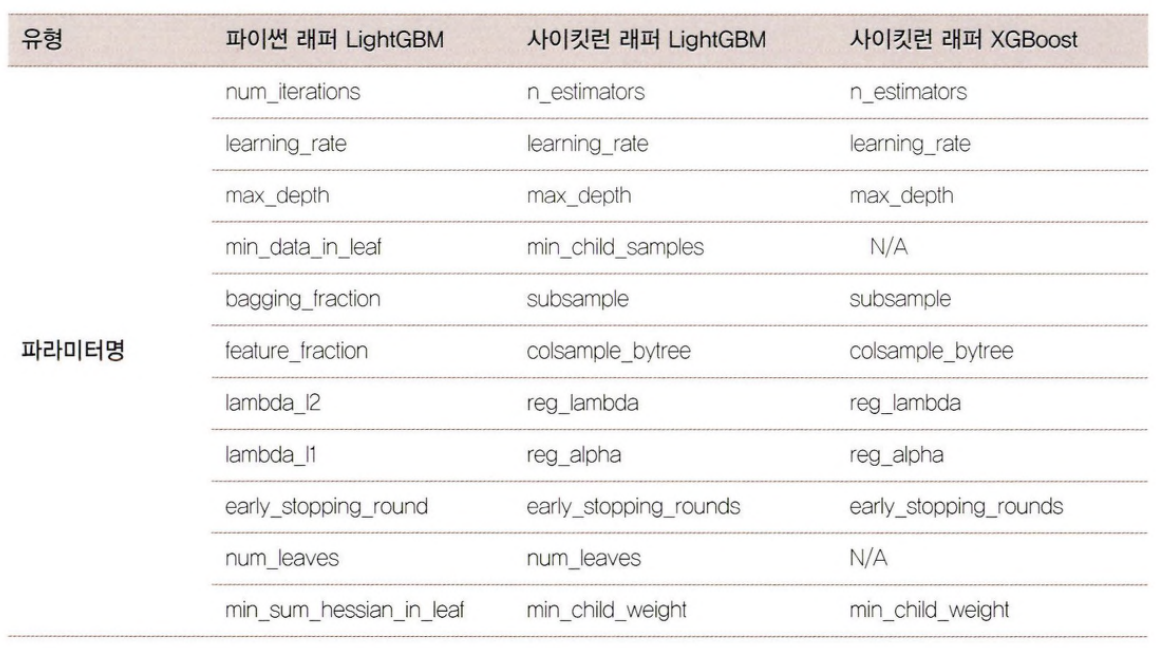

# LightGBM - 위스콘신 유방암 예측

- LightGBM의 파이썬 패키지인 lightgbm에서 LGBMClassifier를 임포트해 사용
- LightGBM도 XGBoost와 동일하게 조기 중단(early stopping)0] 가능
- XGBClassifier와 동일하게 LGBMClassifier의 fit( )에 조기 중단 관련 파라미터를 설정해주면 된다
- n_estimators는 400으로, early_stopping_rounds는 50으로 설정하고 학습 진행

In [5]:
# LightGBM의 파이썬 패키지인 lightgbm에서 LGBMClassifier 임포트
from lightgbm import LGBMClassifier

import pandas as pd
import numpy as mp
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

dataset=load_breast_cancer()

cancer_df=pd.DataFrame(data=dataset.data, columns=dataset.feature_names)
cancer_df['target']=dataset.target
X_features=cancer_df.iloc[:, :-1]
y_label=cancer_df.iloc[:, -1]

# 전체 데이터 중 80%는 학습용 데이터, 20%는 테스트용 데이터 추출
X_train, X_test, y_train, y_test=train_test_split(X_features,y_label, test_size=0.2, random_state=156)

# 위에서 만든 X_trian, y_train을 다시 쪼개서 90%는 학습과 10%는 검증용 데이터로 분리
X_tr, X_val, y_tr, y_val=train_test_split(X_train, y_train, test_size=0.1, random_state=156)

# 앞서 XGBoost와 동일하게 조기 중단 수행 가능
lgbm_wrapper=LGBMClassifier(n_estimators=400, learning_rate=0.05)

#  LightGBM도 XGBoost와 동일하게 조기 중단 수행 가능
evals=[(X_tr, y_tr), (X_val, y_val)]

lgbm_wrapper.fit(X_tr, y_tr, early_stopping_rounds=50, eval_metric="logloss", eval_set=evals, verbose=True)
preds=lgbm_wrapper.predict(X_test)
pred_proba=lgbm_wrapper.predict_proba(X_test)[:, 1]


/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:726: UserWarning: 'early_stopping_rounds' argument is deprecated and will be removed in a future release of LightGBM. Pass 'early_stopping()' callback via 'callbacks' argument instead.
  _log_warning("'early_stopping_rounds' argument is deprecated and will be removed in a future release of LightGBM. "
/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:736: UserWarning: 'verbose' argument is deprecated and will be removed in a future release of LightGBM. Pass 'log_evaluation()' callback via 'callbacks' argument instead.
  _log_warning("'verbose' argument is deprecated and will be removed in a future release of LightGBM. "


[1]	training's binary_logloss: 0.625671	valid_1's binary_logloss: 0.628248
[2]	training's binary_logloss: 0.588173	valid_1's binary_logloss: 0.601106
[3]	training's binary_logloss: 0.554518	valid_1's binary_logloss: 0.577587
[4]	training's binary_logloss: 0.523972	valid_1's binary_logloss: 0.556324
[5]	training's binary_logloss: 0.49615	valid_1's binary_logloss: 0.537407
[6]	training's binary_logloss: 0.470108	valid_1's binary_logloss: 0.519401
[7]	training's binary_logloss: 0.446647	valid_1's binary_logloss: 0.502637
[8]	training's binary_logloss: 0.425055	valid_1's binary_logloss: 0.488311
[9]	training's binary_logloss: 0.405125	valid_1's binary_logloss: 0.474664
[10]	training's binary_logloss: 0.386526	valid_1's binary_logloss: 0.461267
[11]	training's binary_logloss: 0.367027	valid_1's binary_logloss: 0.444274
[12]	training's binary_logloss: 0.350713	valid_1's binary_logloss: 0.432755
[13]	training's binary_logloss: 0.334601	valid_1's binary_logloss: 0.421371
[14]	training's binary

In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
def get_clf_eval(y_test, pred, pred_proba):
  confusion=confusion_matrix(y_test, pred)
  accuracy=accuracy_score(y_test, pred)
  precision=precision_score(y_test, pred)
  recall=recall_score(y_test, pred)
  f1=f1_score(y_test, pred)

  #ROC-AUC 추가
  roc_auc=roc_auc_score(y_test, pred_proba)
  print('오차행렬')
  print(confusion)

  #ROC-AUC print 추가
  print('정확도:{0:.4f}, 정밀도:{1:.4f}, 재현율{2:.4f}, F1:{3:.4f}, AUC:{4:.4f}'.format(accuracy, precision, recall,f1,roc_auc))

In [7]:
get_clf_eval(y_test, preds, pred_proba)

오차행렬
[[34  3]
 [ 2 75]]
정확도:0.9561, 정밀도:0.9615, 재현율0.9740, F1:0.9677, AUC:0.9877


<Axes: title={'center': 'Feature importance'}, xlabel='Feature importance', ylabel='Features'>

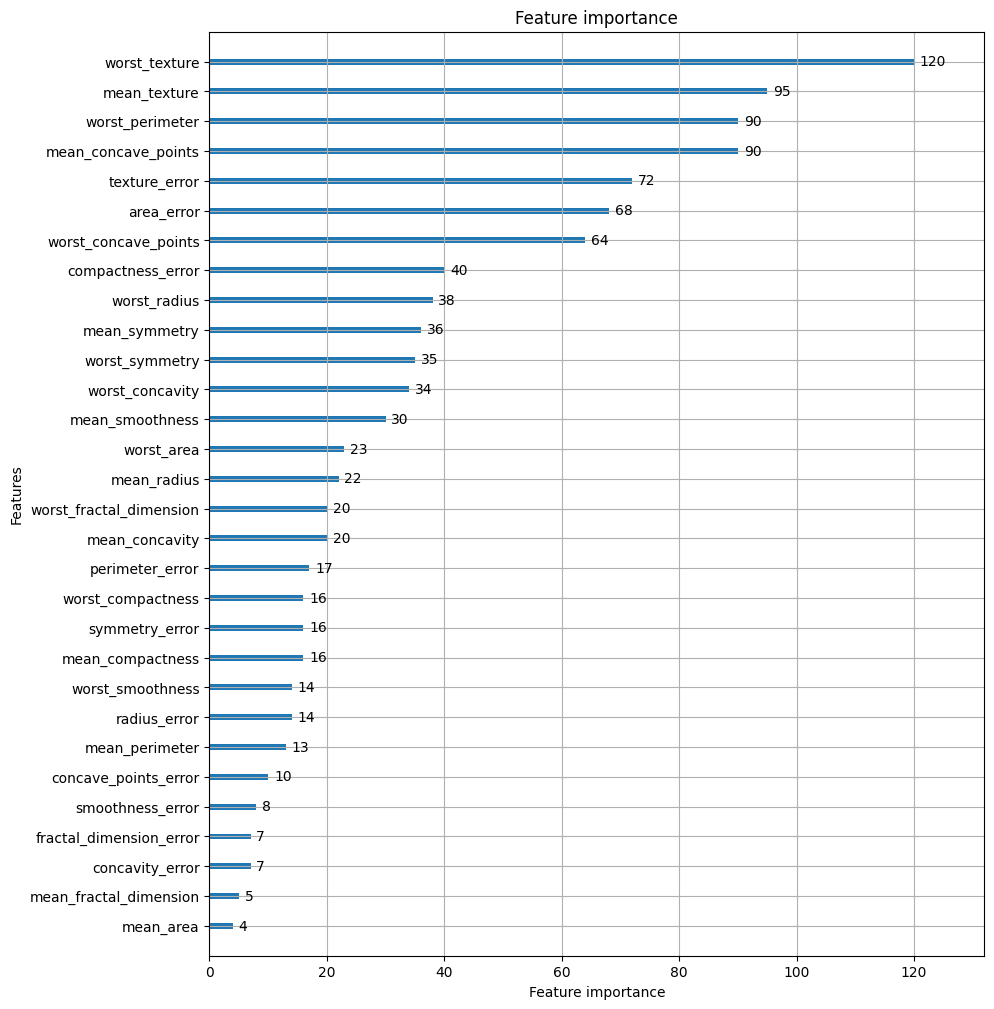

In [8]:
from ast import increment_lineno
# plot_importance()를 이용하여 feature 중요도 시각화
from lightgbm import plot_importance
import matplotlib.pyplot as plt
%matplotlib inline

fig, ax=plt.subplots(figsize=(10, 12))
plot_importance(lgbm_wrapper, ax=ax)

# 베이지안 최적화 기반의 HyperOpt를 이용한 하이퍼 파라미터 튜닝

Grid Search 방식은 한 가지 주요한 단점이 있는데, 튜닝해야 할 하이퍼 파라미터 개수가 많을 경
우 최적화 수행 시간이 오래 걸린다는 것 + 개별 하이퍼 파라미터 값의 범위가 넓거나 학습 데이터가 대용량일 경우에는 최적화 시간이 더욱 늘어난다


XGBoost나 LightGBM은 성능이 매우 뛰어난 알고리즘이지만, 하이퍼 파라미터 개수가 다른 알고리
즘에 비해서 많다.
- 때문에 실무의 대용량 학습 데이터에 Grid Search 방식으로 최적 하이퍼 파라미터를 찾으려면 많은 시간이 소모될 수 있다


In [9]:
params = {
    'max_depth': [10, 20, 30, 40, 50], 'num_leaves': [35, 45, 55, 65],
    'colsample_bytree': [0.5, 0.6, 0.7, 0.8, 0.9], 'subsample': [0.5, 0.6, 0.7, 0.8, 0.9],
    'min_child_weight': [10, 20, 30, 40], 'reg_alpha': [0.01, 0.05, 0.1]
}

이렇게 XGBoostQ LightGBM에 Grid Search를 적용할 경우 기하급수적으로 늘어나는 하이퍼 파라
미터 최적화 시간 때문에 어쩔 수 없이 하이퍼 파라미터 개수를 줄이거나 개별 하이퍼 파라미터의 범위를 줄여야 한다

# 베이지안 최적화 개요

베이지안 최적화: 목적 함수 식을 제대로 알 수 없는 블랙 박스 형태의 함수에서 최대 또는 최소 함
수 반환 값을 만드는 최적 입력값을 가능한 적은 시도를 통해 빠르고 효과적으로 찾아주는 방식

** 특정 함수 식을 알고 있다고 가정

가령 함수 f(x, y) = 2x - 3y가 있다고 하면
f(x, y)의 반환 값을 최대/최소로 하는 x, y값을 찾아내는 것
- x는 크면 클수록(x 값의 범위가
0~1000이라면 1000), y는 0일 경우 가장 최대의 값을 반환


하지만 함수 식 자체를 알 수 없고, 단지 입력값과 반환값만 알 수 있는 상황에서 함수 반환값의 최대/
최소값을 찾기란 매우 어렵다
- 입력값을 순차적으로 대입해서는 결코 짧은 시간 안에 최적 입력값을 찾을 수가 없다
- 이때 베이지안 최적화를 이용하면 쉽고 빠르게 최적 입력값을 찾을 수 있다

베이지안 확률 - 새로운 사건의 관측이나 새로운 샘플 데이터를 기반으로 사후 확률을 개선해 나감

베이지안 최적화 - 새로운 데이터를 입력받았을 때 최적 함수를 예측하는 사후 모델을 개선해 나
가면서 최적 함수 모델을 만들어 낸다

베이지안 최적화를 구성하는 두 가지 중요 요소
- 대체 모델(Surrogate Model) & 획득 함수(Acquisition Function)

  - 대체 모델: 획득 함수로부터 최적 함수를 예측할 수 있는 입력값을 추천 받은 뒤 이를 기반으로 최적 함수 모델을 개선해 나간다
  - 획득 함수: 개선된 대체 모델을 기반으로 최적 입력값을 계산한다

[베이지안 최적화 단계]
- Step 1: 최초에는 랜덤하게 하이퍼 파라미터들을 샘플링하고 성능 결과를 관측
  - 아래 그림에서 검은색 원은 특정 하이퍼 파라미터가 입력되었을 때 관측된 성능 지표 결괏값을 뜻하며 주황색 사선은 찾아야 할 목표 최적함수이다
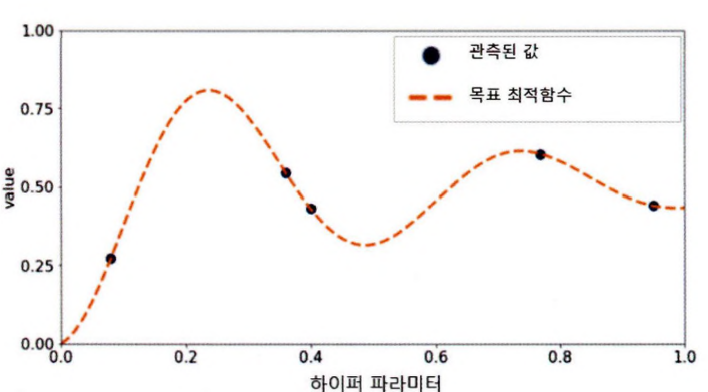

- Step 2: 관측된 값을 기반으로 대체 모델은 최적 함수를 추정
  - 아래 그림에서 파란색 실선은 대체 모델이 추정한 최적함수이다.
  - 옅은 파란색으로 되어 있는 영역은 예측된 함수의 신뢰 구간이고 추정된 함수의 결괏값 오류 편차를 의미하며 추정 함수의 불확실성을 나타낸다
  - 최적 관측값은 y축 value에서 가장 높은 값을 가질 때의 하이퍼 파라미터이다
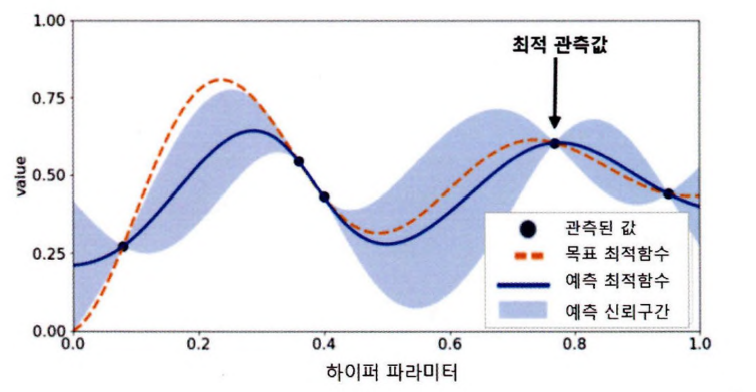

- Step 3: 추정된 최적 함수를 기반으로 획득 함수(Acquisition Function)는 다음으로 관측할 하이퍼 파라미터 값을 계산한다
  - 획득 함수는 이전의 최적 관측값보다 더 큰 최댓값을 가질 가능성이 높은 지점을 찾아서 다음에 관측할 하이퍼 파라미터를 대체 모델에 전달한다
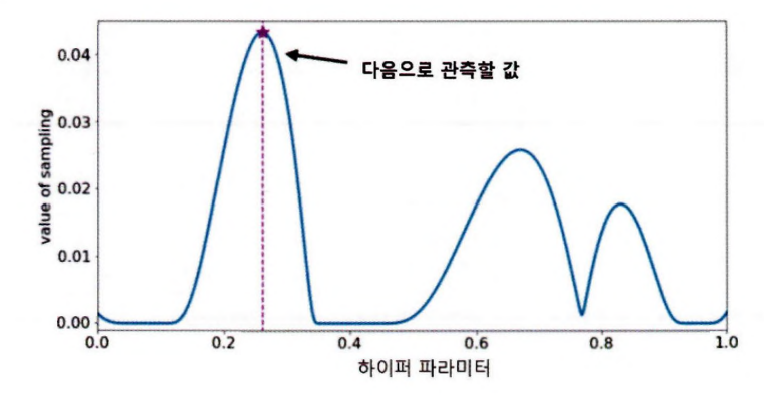

- Step 4: 획득 함수로부터 전달된 하이퍼 파라미터를 수행하여 관측된 값을 기반으로 대체 모델은 갱신되어 다시 최적 함수를 예측 추정
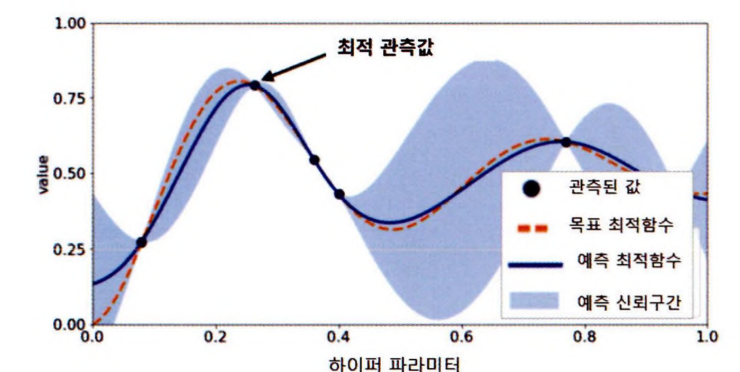

이런 방식으로 Step 3와 Step 4를 특정 횟수만큼 반복하게 되면 대체 모델의 불확실성이 개선되고 점
차 정확한 최적 함수 추정이 가능하게 한다

# HyperOpt 사용하기

In [10]:
pip install hyperopt

 <HyperOpt 활용하는 주요 로직>
- 첫째: 입력 변수명과 입력값의 검색 공간(Search Space) 설정
- 둘째: 목적 함수(Objective Function)의 설정
- 마지막: 목적 함수의 반환 최솟값을 가지는 최적 입력값을 유추

In [11]:
from hyperopt import hp

# -10 ~10까지 1 간격을 가지는 입력 변수 x와 -15 ~ 15까지 1간격으로 입력 변수 y 설정.
search_space = {'x': hp.quniform('x', -10, 10, 1), 'y': hp.quniform('y', -15, 15, 1) }

<입력값의 검색 공간을 제공하는 대표적인 함수>
- low는 최솟값, high는 최댓값이며 이는 간격

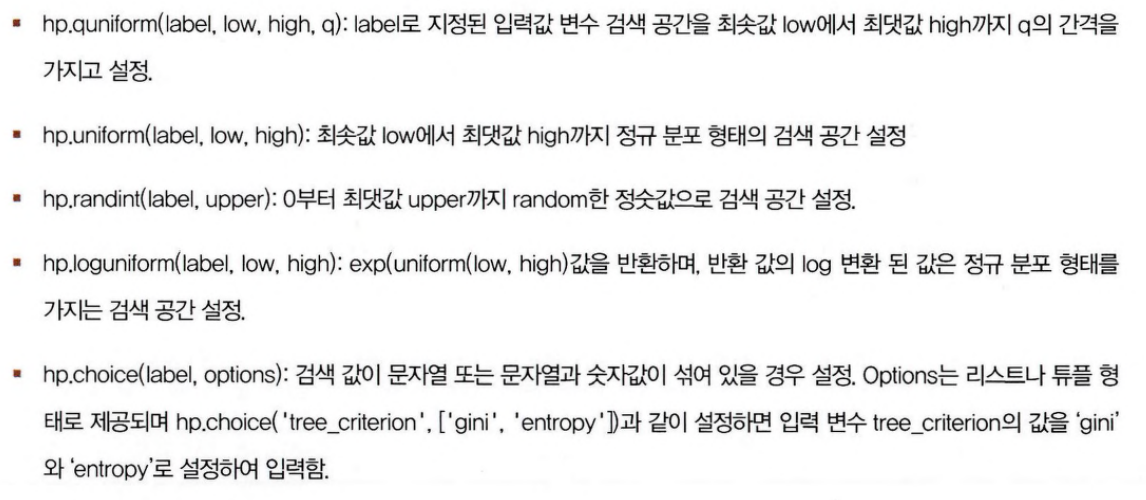

In [12]:
#from hyperopt import STATUS_0K

# 목적 함수를 생성. 변숫값과 변수 검색 공간을 가지는 딕셔너리를 인자로 받고, 특정 값을 반환
def objective_func(search_space):
  x=search_space['x']
  y=search_space['y']
  retval=x**2 - 20*y

  return retval

HyperOpt는 이러한 기능을 수행할 수
있도록 fmin(objective, space, algo, max_evals, trials) 함수를 제공


<fmin() 함수의 주요인자>
- fn： 위에서 생성한 objective_func 같은 목적 함수
- space： 위에서 생성한 search_space와 같은 검색 공간 딕셔너리
- algo： 베이지안 최적화 적용 알고리즘, 기본적으로 tpe.suggest이며 이는 HyperOpt의 기본 최적화 알고리즘인 TPE(Tree of Parzen Estimator)를 의미한다
- max_evals： 최적 입력값을 찾기 위한 입력값 시도 횟수
- trials： 최적 입력값을 찾기 위해 시도한 입력값 및 해당 입력값의 목적 함수 반환값 결과를 저장하는 데 사용된다. Trials 클래스를 객체로 생성한 변수명을 입력한다
- rstate： fmin()을 수행할 때마다 동일한 결괏값을 가질 수 있도록 설정하는 랜덤 시드(seed) 값이다

In [16]:
import numpy as np
from hyperopt import fmin, tpe, Trials

# 입력 결괏값을 저장한 Trials 객체값 생성.
trial_val = Trials()

# 목적 함수의 최솟값을 반환하는 최적 입력 변숫값을 5번의 입력값 시도(max_evals=5)로 찾아냄.
best_01 = fmin(fn=objective_func, space=search_space, algo=tpe.suggest, max_evals=5, trials=trial_val, rstate=np.random.default_rng(seed=0))
print('best:', best_01)

100%|██████████| 5/5 [00:00<00:00, 157.60trial/s, best loss: -224.0]
best: {'x': np.float64(-4.0), 'y': np.float64(12.0)}


In [17]:
trial_val = Trials()

# max_evals를 20회로 늘려서 재테스트
best_02 = fmin(fn=objective_func, space=search_space, algo=tpe.suggest, max_evals=20, trials=trial_val, rstate=np.random.default_rng(seed=0))
print('best:', best_02)

100%|██████████| 20/20 [00:00<00:00, 183.00trial/s, best loss: -296.0]
best: {'x': np.float64(2.0), 'y': np.float64(15.0)}


-> 만일 그리드 서치와 같이 순차적으로 x, y 변숫값
을 입력해서 최소 함수 반환값을 찾는다면 최대 21x31=651회의 반복이 필요할 수도 있는데 반해서,
베이지안 최적화를 이용해서는 20회의 반복만으로 일정 수준의 최적값을 근사해 낼 수 있었다
- 최적 값을 찾는 시간을 많이 줄여 줄 수 있다는 것은 알 수 있다

In [18]:
# fmin( )에 인자로 들어가는 Trials 객체의 result 속성에 파이썬 리스트로 목적 함수 반환값들이 저장됨
# 리스트 내부의 개별 원소는 {'loss'：함수 반환값, 'status'：반환 상태값}와 같은 딕셔너리임.
print(trial_val.results)

[{'loss': -64.0, 'status': 'ok'}, {'loss': -184.0, 'status': 'ok'}, {'loss': 56.0, 'status': 'ok'}, {'loss': -224.0, 'status': 'ok'}, {'loss': 61.0, 'status': 'ok'}, {'loss': -296.0, 'status': 'ok'}, {'loss': -40.0, 'status': 'ok'}, {'loss': 281.0, 'status': 'ok'}, {'loss': 64.0, 'status': 'ok'}, {'loss': 100.0, 'status': 'ok'}, {'loss': 60.0, 'status': 'ok'}, {'loss': -39.0, 'status': 'ok'}, {'loss': 1.0, 'status': 'ok'}, {'loss': -164.0, 'status': 'ok'}, {'loss': 21.0, 'status': 'ok'}, {'loss': -56.0, 'status': 'ok'}, {'loss': 284.0, 'status': 'ok'}, {'loss': 176.0, 'status': 'ok'}, {'loss': -171.0, 'status': 'ok'}, {'loss': 0.0, 'status': 'ok'}]


-> max_evals=20으로 fmin() 함수는 20회의 반복 수행을 했으므로 results 속성은 loss와 stat나s를 키
값으로 가지는 20개의 딕셔너리를 개별 원소를 가지는 리스트로 구성되어 있음

In [19]:
# Trials 객체의 vals 속성에 {'입력변수명': 개별 수행 시마다 입력된 값 리스트} 형태로 저장됨.
print(trial_val.vals)

{'x': [np.float64(-6.0), np.float64(-4.0), np.float64(4.0), np.float64(-4.0), np.float64(9.0), np.float64(2.0), np.float64(10.0), np.float64(-9.0), np.float64(-8.0), np.float64(-0.0), np.float64(-0.0), np.float64(1.0), np.float64(9.0), np.float64(6.0), np.float64(9.0), np.float64(2.0), np.float64(-2.0), np.float64(-4.0), np.float64(7.0), np.float64(-0.0)], 'y': [np.float64(5.0), np.float64(10.0), np.float64(-2.0), np.float64(12.0), np.float64(1.0), np.float64(15.0), np.float64(7.0), np.float64(-10.0), np.float64(0.0), np.float64(-5.0), np.float64(-3.0), np.float64(2.0), np.float64(4.0), np.float64(10.0), np.float64(3.0), np.float64(3.0), np.float64(-14.0), np.float64(-8.0), np.float64(11.0), np.float64(-0.0)]}


-> vals는 딕셔너리 형태의 값을 가지며, 입력 변수 x와y를 키값으로 가지며, x와y 키 값의 밸류는 20회
의 반복 수행 시마다 사용되는 입력값들을 리스트 형태로 가지고 있는 것을 알 수 있다

In [20]:
import pandas as pd

# results에서 loss 키값에 해당하는 밸류들을 추출하여 list로 생성.
losses = [loss_dict['loss'] for loss_dict in trial_val.results]

# DataFrame으로 생성 .
result_df = pd.DataFrame({'x': trial_val.vals['x'], 'y': trial_val.vals['y'], 'losses': losses})
result_df

,x,y,losses
0,-6.0,5.0,-64.0
1,-4.0,10.0,-184.0
2,4.0,-2.0,56.0
3,-4.0,12.0,-224.0
4,9.0,1.0,61.0
5,2.0,15.0,-296.0
6,10.0,7.0,-40.0
7,-9.0,-10.0,281.0
8,-8.0,0.0,64.0
9,-0.0,-5.0,100.0


==> 수행 횟수별 입력 변수 x, y와 반환값 loss 확인

# HyperOpt를 이용한 XGBoost 하이퍼 파라미터 최적화

- 적용해야 할 하이퍼 파라미터와 검색 공간을 설정
- 목적 함수에서 XGBoost를 학습 후에
예측 성능 결과를 반환 값으로 설정
- 그리고 fmin() 함수에서 목적 함수를 하이퍼 파라미터 검색 공간의 입력값들을 사용하여 최적의 예측 성능 결과를 반환하는 최적 입력값들을 결정하는 것

주의 **
- 특정 하이퍼 파라미터들은 정숫값만 입력은 받
는데 HyperOpt는 입력값과 반환 값이 모두 실수형이기 때문에 하이퍼 파라미터 입력 시 형변환을 해
줘야 한다
- HyperOpt의 목적 함수는 최솟값을 반환할 수 있도록 최적화해야 하기 때문에 성능 값이 클수록 좋은 성능 지표일 경우 -1을 곱해 줘야 한다

In [21]:
# 전체 데이터 중 80%는 학습용 데이터, 20%는 테스트용 데이터 추출
X_train, X_test, y_train, y_test=train_test_split(X_features, y_label, test_size=0.2, random_state=156 )

# 앞에서 추출한 학습 데이터를 다시 학습과 검증 데이터로 분리
X_tr, X_val, y_tr, y_val= train_test_split(X_train, y_train, test_size=0.1, random_state=156 )

In [22]:
from hyperopt import hp

# max_depth는 5에서 20까지 1간격으로, min_child_weight는 1에서 2까지 1간격으로
# colsample_bytree는 0.5에서 1 사이, learning_rate는 0.01 에서 0.2 사이 정규 분포된 값으로 검색
xgb_search_space = {'max_depth': hp.quniform('max_depth', 5, 20, 1),
                    'min_child_weight': hp.quniform('min_child_weight', 1, 2, 1),
                    'learning_rate': hp.uniform('learning_rate',  0.01, 0.2),
                    'colsample_bytree': hp.uniform('colsample_bytree', 0.5, 1),
}

<목적 함수 설정>
- 하이퍼 파라미터 튜닝을 위한 목적 함수는 검색 공간에서 설정한 하이퍼 파라미터들을 입력받아서 XGBoost를 학습하고 평가지표를 반환할 수 있도록 구성

** 유의점
- 1. 검색 공간에서 목적 함수로 입력되는 모든 인자들은 실수형 값이므로 이들을 XGBoostClassifier의 정수형 하이퍼 파라미터값으로 설정할 때는 정수형으로 형변환을 해야 한다
  - hp.quniform('max_depth', 5, 20, 1)를 적용해도 검색되는 값은 [5, 6, 7, …]과
같은 일련의 정수형 값이 아니라 [5.0, 6.0, 7.0, …]과 같은 실수형 값이 입력된다
- 2. HyperOpt의 목적 함수는 최솟값을 반환할 수 있도록 최적화해야 하기 때문에 정확도와 같
이 값이 클수록 좋은 성능 지표일 경우 -1을 곱한 뒤 반환하여, 더 큰 성능 지표가 더 작은 반환값이 되
도록 만들어 줘야 한다
  - 목적 함수의 반환값을 정확도로 한다면, 정확도는 값이 클수록 좋은 성능 지표이므로 당연히 0.8(80%) 보다는 0.9(90%)가 더 좋은 지표이다


In [23]:
from sklearn.model_selection import cross_val_score
from xgboost import XGBClassifier
from hyperopt import STATUS_OK

# fmin()에서 입력된 search_space 값으로 입력된 모든 값은 실수형임.
# XGBClassifier의 정수형 하이퍼 파라미터는 정수형 변환을 해줘야 함.
# 정확도는 높을수록 더 좋은 수치임. -1 * 정확도를 곱해서 큰 정확도 값일수록 최소가 되도록 변환
def objective_func(search_space):
  # 수행 시간 절약을 위해 nestimators는 100으로 축소
  xgb_clf = XGBClassifier(n_estimators=100, max_depth=int(search_space['max_depth']),
                          min_child_weight=int(search_space['min_child_weight']),
                          learning_rate=search_space['learning_rate'],
                          colsample_bytree=search_space['colsample_bytree'],
                          eval_metric='logloss')
  accuracy = cross_val_score(xgb_clf, X_train, y_train, scoring='accuracy', cv=3)

  # accuracy는 cv=3 개수만큼 roc-auc 결과를 리스트로 가짐. 이를 평균해서 반환하되 -1을 곱함.
  return {'loss': -1*np.mean(accuracy), 'status': STATUS_OK}

In [24]:
from hyperopt import fmin, tpe, Trials

trial_val=Trials()
best=fmin(fn=objective_func,
            space=xgb_search_space,
            algo=tpe.suggest,
            max_evals=50, # 최대 반복 횟수를 지정합니다.
            trials=trial_val, rstate=np.random.default_rng(seed=9))
print('best:', best)

100%|██████████| 50/50 [00:20<00:00,  2.42trial/s, best loss: -0.9714476588823051]
best: {'colsample_bytree': np.float64(0.5041680558682833), 'learning_rate': np.float64(0.13493661826434478), 'max_depth': np.float64(18.0), 'min_child_weight': np.float64(2.0)}


In [25]:
print('colsample_bytree：{0}, learning_rate：{1}, max_depth：{2}, min_child_weight：{3}'.format(
  round(best['colsample_bytree'], 5), round(best['learning_rate'], 5),
  int(best['max_depth']), int(best['min_child_weight'])))

colsample_bytree：0.50417, learning_rate：0.13494, max_depth：18, min_child_weight：2


In [26]:
# 1. 객체 생성 시 early_stopping_rounds와 eval_metric 지정
xgb_wrapper = XGBClassifier(
    n_estimators=400,
    learning_rate=round(best['learning_rate'], 5),
    max_depth=int(best['max_depth']),
    min_child_weight=int(best['min_child_weight']),
    colsample_bytree=round(best['colsample_bytree'], 5),
    early_stopping_rounds=50,
    eval_metric='logloss'
)

evals = [(X_tr, y_tr), (X_val, y_val)]

# 2. fit()에서는 early_stopping_rounds와 eval_metric 제거
xgb_wrapper.fit(X_tr, y_tr, eval_set=evals, verbose=True)

preds = xgb_wrapper.predict(X_test)
pred_proba = xgb_wrapper.predict_proba(X_test)[:, 1]

get_clf_eval(y_test, preds, pred_proba)

[0]	validation_0-logloss:0.56084	validation_1-logloss:0.57845
[1]	validation_0-logloss:0.48008	validation_1-logloss:0.51915
[2]	validation_0-logloss:0.41538	validation_1-logloss:0.47155
[3]	validation_0-logloss:0.36378	validation_1-logloss:0.43536
[4]	validation_0-logloss:0.31836	validation_1-logloss:0.40463
[5]	validation_0-logloss:0.28115	validation_1-logloss:0.38355
[6]	validation_0-logloss:0.24955	validation_1-logloss:0.36422
[7]	validation_0-logloss:0.22336	validation_1-logloss:0.34979
[8]	validation_0-logloss:0.20006	validation_1-logloss:0.33591
[9]	validation_0-logloss:0.18086	validation_1-logloss:0.32508
[10]	validation_0-logloss:0.16536	validation_1-logloss:0.31240
[11]	validation_0-logloss:0.15137	validation_1-logloss:0.30903
[12]	validation_0-logloss:0.13863	validation_1-logloss:0.30274
[13]	validation_0-logloss:0.12744	validation_1-logloss:0.29597
[14]	validation_0-logloss:0.11801	validation_1-logloss:0.29526
[15]	validation_0-logloss:0.10979	validation_1-logloss:0.29458
[1

# **스태킹 앙상블**

스태킹 모델
- 두가지 필요 => 첫 번째는 개별적인 기반 모델이고, 두 번째 이 개별 기반 모델의 예측 데이터를 학습 데이터로 만들어서 학습하는 최종 메타 모델
- 핵심
  - 여러 개별 모델의 예측 데이터를 각각 스태킹 형태로 결합해 최종 메타 모델의 학습용 피처 데이터 세트와 테스트용 피처 데이터 세트를 만드는 것

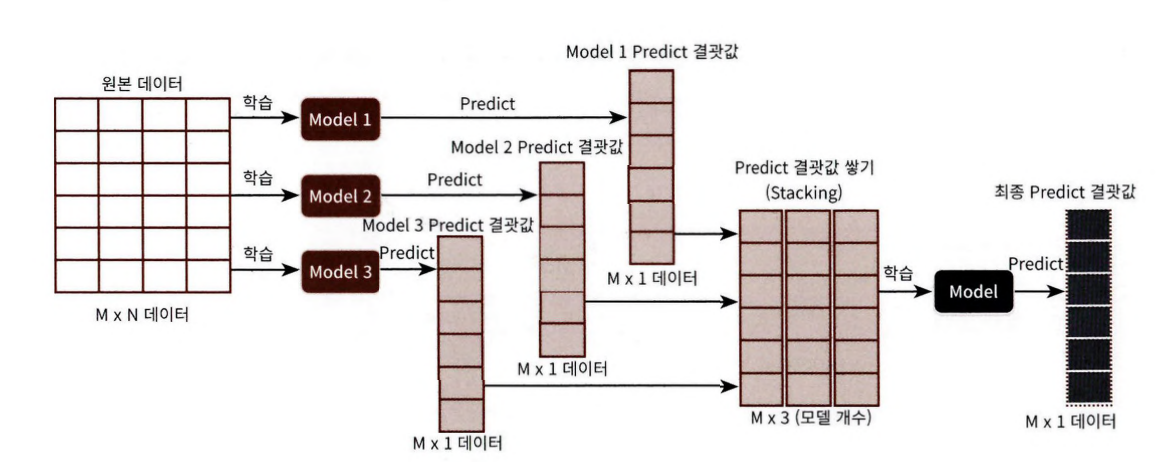

M개의 로우, N개의 피처（칼럼）를 가진 데이터 세트에 스태킹 앙상블을 적용한다고 가정
- 학습에 사용할 ML 알고리즘 모델은 모두 3개
  - 먼저 모델별로 각각 학습을 시킨 뒤 예측
  을 수행하면 각각 M개의 로우를 가진 1 개의 레이블 값을 도출
  - 모델별로 도출된 예측 레이
  블 값을 다시 합해서（스태킹） 새로운 데이터 세트를 만들고 이렇게 스태킹된 데이터 세트에 대해 최종 모델을 적용해 최종 예측

# 기본 스태킹 모델

In [27]:
import numpy as np

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

cancer_data = load_breast_cancer()

X_data = cancer_data.data
y_label = cancer_data.target
X_train, X_test, y_train, y_test = train_test_split(X_data, y_label, test_size=0.2, random_state=0)

In [28]:
# 개별 모델 ML 모델 생성
knn_clf = KNeighborsClassifier(n_neighbors=4)
rf_clf = RandomForestClassifier(n_estimators=100, random_state=0)
dt_clf = DecisionTreeClassifier()
ada_clf = AdaBoostClassifier(n_estimators=100)

# 스태킹으로 만들어진 데이터 세트를 학습, 예측할 최종 모델
lr_final = LogisticRegression()

In [29]:
# 개별 모델들을 학습.
knn_clf.fit(X_train, y_train)
rf_clf.fit(X_train, y_train)
dt_clf.fit(X_train, y_train)
ada_clf.fit(X_train, y_train)

AdaBoostClassifier(n_estimators=100)

In [30]:
# 학습된 개별 모델들이 각자 반환하는 예측 데이터 세트를 생성하고 개별 모델의 정확도 측정.
knn_pred = knn_clf.predict(X_test)
rf_pred = rf_clf.predict(X_test)
dt_pred = dt_clf.predict(X_test)
ada_pred = ada_clf.predict(X_test)
print('KNN 정확도: {0:.4f}'.format(accuracy_score(y_test, knn_pred)))
print('랜덤 포레스트 정확도: {0:.4f}'.format(accuracy_score(y_test, rf_pred)))
print('결정 트리 정확도: {0:.4f}'.format(accuracy_score(y_test, dt_pred)))
print('에이다부스트 정확도: {0:.4f}'.format(accuracy_score(y_test, ada_pred)))

KNN 정확도: 0.9211
랜덤 포레스트 정확도: 0.9649
결정 트리 정확도: 0.9123
에이다부스트 정확도: 0.9737


In [31]:
## 개별 알고리즘으로부터 예측된 값을 칼럼 레벨로 옆으로 붙여서 피처값으로 만들어, 최종 메타 모델인 로지스틱 회귀에서 학습 데이터로 다시 사용
pred = np.array([knn_pred, rf_pred, dt_pred, ada_pred])
print(pred.shape)

# transpose를 이용해 행과 열의 위치 교환. 칼럼 레벨로 각 알고리즘의 예측 결과를 피처로 만듦.
pred = np.transpose(pred)
print(pred.shape)

(4, 114)
(114, 4)


In [32]:
## 예측 데이터로 생성된 데이터 세트를 기반으로 최종 메타 모델인 로지스틱 회귀를 학습하고 예측 정확도를 측정
lr_final.fit(pred, y_test)
final = lr_final.predict(pred)
print('최종 메타 모델의 예측 정확도: {0:.4f}'.format(accuracy_score(y_test, final)))

최종 메타 모델의 예측 정확도: 0.9737


# CV 세트 기반의 스태킹 - 과적합 개선

과적합을 개선하기 위해 최종 메타 모델을 위한 데이터 세트를 만들 때 교차 검증 기반으로 예측된 결과 데이터 세트를 이용

CV 세트 기반의 스태킹은 이에 대한 개선을 위해 개별 모델들이 각각 교차 검증으로 메타 모델을 위한
학습용 스태킹 데이터 생성과 예측을 위한 테스트용 스태킹 데이터를 생성한 뒤 이를 기반으로 메타 모
델이 학습과 예측수행
- 스텝 1: 각 모델별로 원본 학습/테스트 데이터를 예측한 결과 값을 기반으로 메타 모델을 위한 학습용/테스트용 데이터를 생성
- 스텝2: 스텝 1에서 개별 모델들이 생성한 학습용 데이터를 모두 스태킹 형태로 합쳐서 메타 모델이 학습할 최종 학습용 데이터 세트를 생성 -> 마찬가지로 각 모델들이 생성한 테스트용 데이터를 모두 스태킹 형태로 합쳐서 메타 모델이 예측
할 최종 테스트 데이터 세트를 생성 / 메타 모델은 최종적으로 생성된 학습 데이터 세트와 원본 학습 데이터의 레이블 데이터를 기반으로 학습한 뒤, 최종적으로 생성된 테스트 데이터 세트를 예측하고, 원본 테스트 데이터의 레이블 데이터를 기반으로 평가

먼저 학습용 데이터를 N개의 폴드(Fold)로 나눈다/  여기서는 3개의 폴드세트로 가정
- 3개의 폴드세트이므로 3번의 유사한 반복 작업을 수행하고, 마지막 3번째 반복에서 개별 모델의 예측
값으로 학습 데이터와 테스트 데이터를 생성

<주요 프로세스>
- 1. 학습용 데이터를 3개의 폴드로 나눈 뒤, 2개의 폴드는 학습을 위한 데이터 폴드로, 나머지는 1개의 폴드는 검증을 위한 데이터 폴드로 나눈다
  - 이렇게 두 개의 폴드로 나뉜 학습 데이터를 기반으로 개별 모델을 학습시킨다
- 2. 이렇게 학습된 개별 모델은 검증 폴드 1개 데이터로 예측하고 그 결과를 저장한다
  - 이렇게 로직을 3번 반복하면서 학습 데이터와 검증 데이터 세트를 변경해 가면서 학습 후 예측 결과를 별도로 저장한다
  - 이렇게 만들어진 예측 데이터는 메타 모델을 학습시키는 학습 데이터로 사용된다
- 3. 2개의 학습 폴드 데이터로 학습된 개별 모델은 원본 테스트 데이터를 예측하여 예측값을 생성한다.
  - 이런 로직을 3번 반복하면서 이 예측값의 평균으로 최종 결괏값을 생성하고 이를 메타 모델을 위한 테스트 데이터로 사용한다

<Step 1>

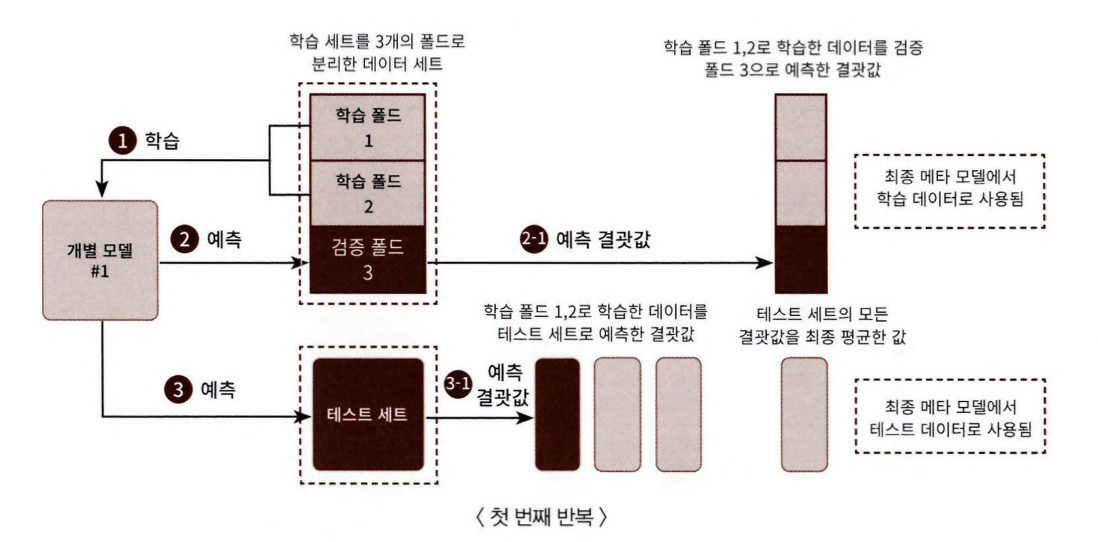

**  3개의 폴드만큼 반복을 수행하면서 스태킹 데이터를 생성하는 첫 번째 반복을 설명

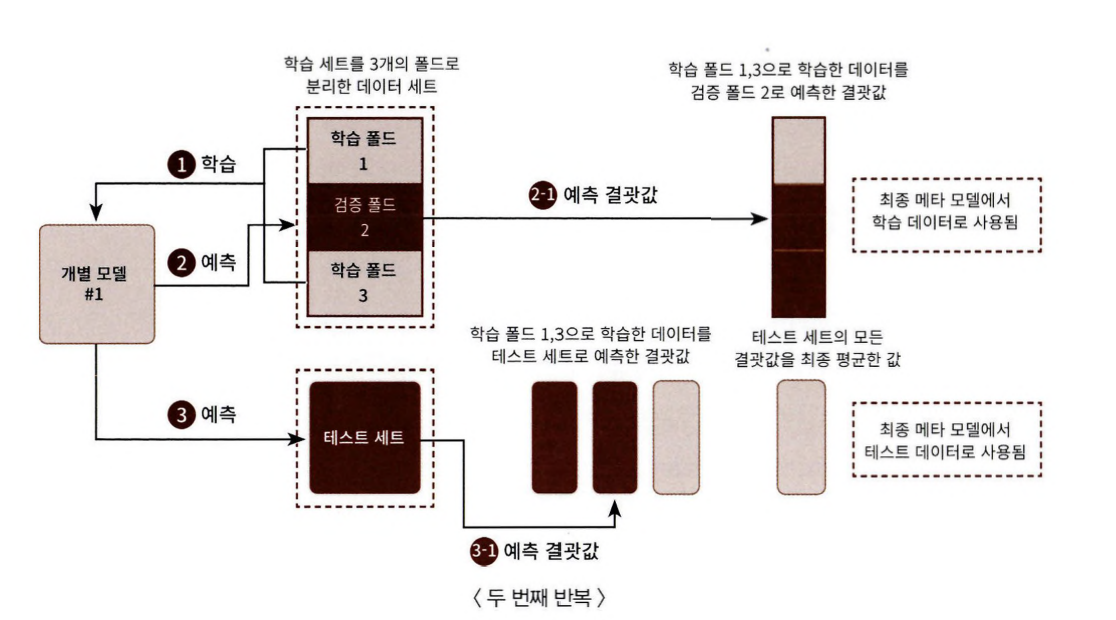

** 스태킹 데이터를 생성하는 두 번째 반복을 설명
- 폴드 내의 학습용 데이터 세트를 변경하고 첫 번째 그림과 동일한 작업을 수행

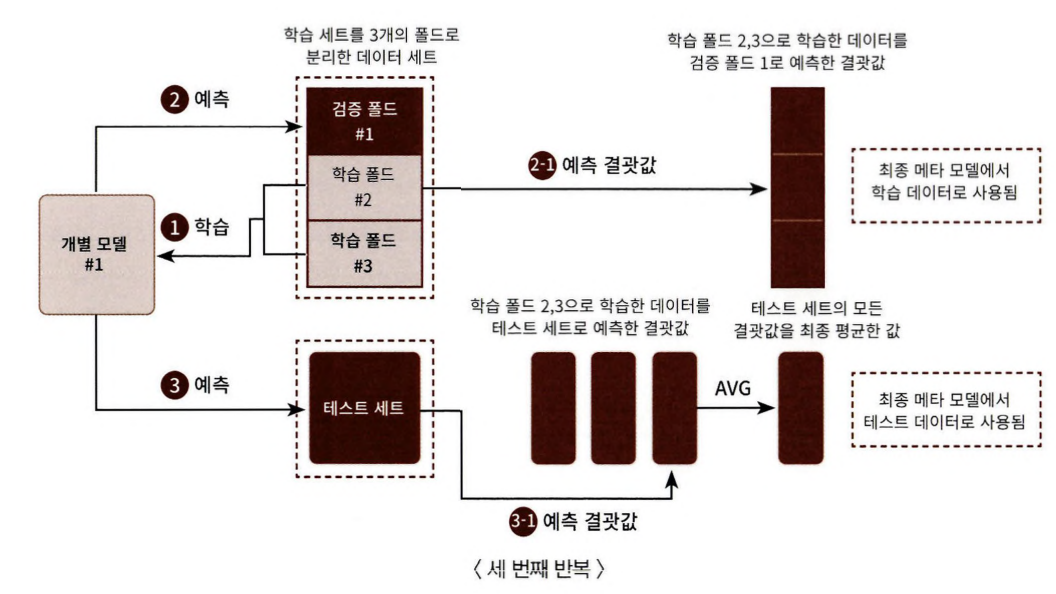

** 스태킹 데이터를 생성하는 세 번째 반복을 설명
- 세 번째 반복을 수행하면서 폴드 내의 학습용 데이터 세트가 변경된다

<Step 2>

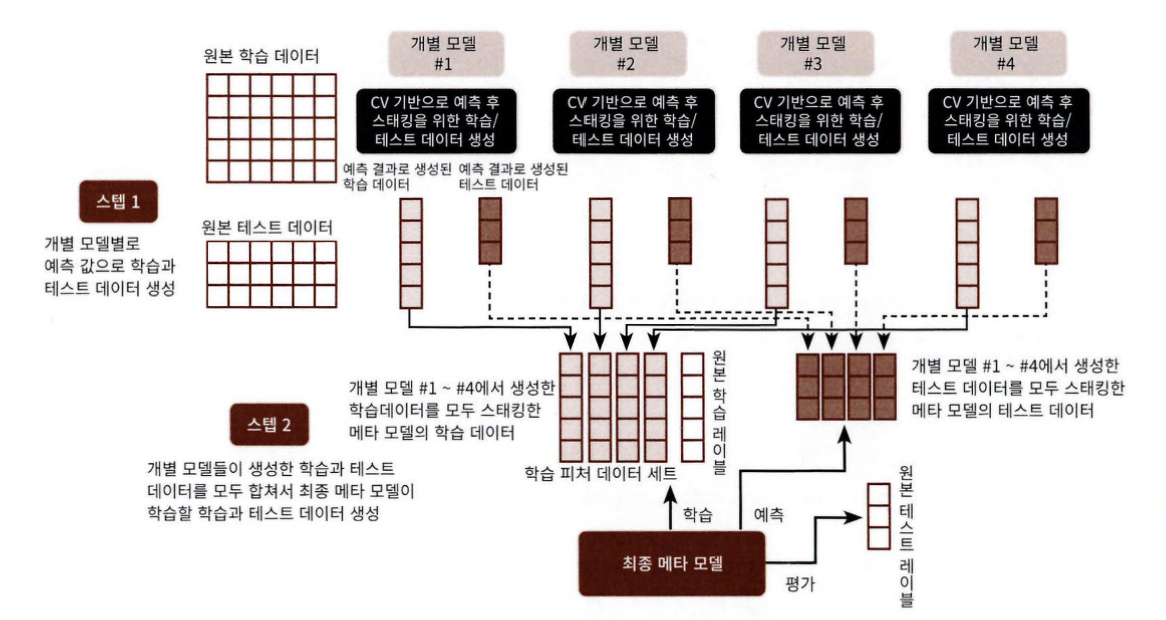

각 모델들이 스텝 1으로 생성한 학습과 테스트 데이터를 모두 합쳐서 최종적으로 메타 모델이 사용할 학습 데이터와 테스트 데이터 생성하기
- 메타 모델이 사용할 최종 학습 데이터와 원본 데이터의 레이블 데이터를 합쳐서 메타 모델을 학습한 후에 최종 테스트 데이터로 예측을 수행한 뒤, 최종 예측 결과를 원본 테스트 데이터의 레이블 데이터와 비교해 평가

In [40]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error

# 개별 기반 모델에서 최종 메타 모델이 사용할 학습 및 테스트용 데이터를 생성하기 위한 함수
def get_stacking_base_datasets(model, X_train_n, y_train_n, X_test_n, n_folds):

  # 지정된 n_folds 값으로 KFold 생성
  kf = KFold(n_splits=n_folds, shuffle=False)

  # 추후에 메타 모델이 사용할 학습 데이터 반환을 위한 넘파이 배열 초기화
  train_fold_pred = np.zeros((X_train_n.shape[0], 1 ))
  test_pred = np.zeros((X_test_n.shape[0], n_folds))
  print(model.__class__.__name__, 'model 시작')

  for folder_counter, (train_index, valid_index)in enumerate(kf.split(X_train_n)):
    # 입력된 학습 데이터에서 기반 모델이 학습/예측할 폴드 데이터 세트 추출
    print('\t폴드 세트:', folder_counter, '시작')
    X_tr = X_train_n[train_index]
    y_tr = y_train_n[train_index]
    X_te = X_train_n[valid_index]

    # # 폴드 세트 내부에서 다시 만들어진 학습 데이터로 기반 모델의 학습 수행.
    model.fit(X_tr, y_tr)
    # 폴드 세트 내부에서 다시 만들어진 검증 데이터로 기반 모델 예측 후 데이터 저장.
    train_fold_pred[valid_index, :] = model.predict(X_te).reshape(-1, 1)
    # 입력된 원본 테스트 데이터를 폴드 세트내 학습된 기반 모델에서 예측 후 데이터 저장.
    test_pred[:, folder_counter] = model.predict(X_test_n)

  # 폴드 세트 내에서 원본  테스트 데이터를 예측한 데이터를 평균하여 테스트 데이터로 생성
  test_pred_mean=np.mean(test_pred, axis=1).reshape(-1, 1)

  # train_fold_pred는 최종 메타 모델이 사용하는 학습 데이터, test_pred_mean은 테스트 데이터
  return train_fold_pred, test_pred_mean

In [41]:
knn_train, knn_test = get_stacking_base_datasets(knn_clf, X_train, y_train, X_test, 7)
rf_train, rf_test = get_stacking_base_datasets(rf_clf, X_train, y_train, X_test, 7)
dt_train, dt_test = get_stacking_base_datasets(dt_clf, X_train, y_train, X_test, 7)
ada_train, ada_test = get_stacking_base_datasets(ada_clf, X_train, y_train, X_test, 7)

KNeighborsClassifier model 시작
	폴드 세트: 0 시작
	폴드 세트: 1 시작
	폴드 세트: 2 시작
	폴드 세트: 3 시작
	폴드 세트: 4 시작
	폴드 세트: 5 시작
	폴드 세트: 6 시작
RandomForestClassifier model 시작
	폴드 세트: 0 시작
	폴드 세트: 1 시작
	폴드 세트: 2 시작
	폴드 세트: 3 시작
	폴드 세트: 4 시작
	폴드 세트: 5 시작
	폴드 세트: 6 시작
DecisionTreeClassifier model 시작
	폴드 세트: 0 시작
	폴드 세트: 1 시작
	폴드 세트: 2 시작
	폴드 세트: 3 시작
	폴드 세트: 4 시작
	폴드 세트: 5 시작
	폴드 세트: 6 시작
AdaBoostClassifier model 시작
	폴드 세트: 0 시작
	폴드 세트: 1 시작
	폴드 세트: 2 시작
	폴드 세트: 3 시작
	폴드 세트: 4 시작
	폴드 세트: 5 시작
	폴드 세트: 6 시작


In [44]:
Stack_final_X_train = np.concatenate((knn_train, rf_train, dt_train, ada_train), axis=1)
Stack_final_X_test = np.concatenate((knn_test, rf_test, dt_test, ada_test), axis=1)
print('원본 학습 피처 데이터 Shape:', X_train.shape, '원본 테스트 피처 Shape：', X_test.shape)
print('스태킹 학습 피처 데이터 Shape：', Stack_final_X_train.shape,
      '스태킹 테스트 피처 데이터 Shape:', Stack_final_X_test.shape)


원본 학습 피처 데이터 Shape: (455, 30) 원본 테스트 피처 Shape： (114, 30)
스태킹 학습 피처 데이터 Shape： (455, 4) 스태킹 테스트 피처 데이터 Shape: (114, 4)


** Stack_final_X_train은 메타 모델이 학습할 학습용 피처 데이터 세트

In [45]:
## 최종 메타 모델인 로지스틱 회귀를 스태킹된 학습용 피처 데이터 세트와 원본 학습 레이블 데이터로 학습한 후에 스태킹된 테스트 데이터 세트로 예측하고, 예측 결과를 원본 테스트 레이블 데이터와 비교해 정확도를 측정
lr_final.fit(Stack_final_X_train, y_train)
stack_final = lr_final.predict(Stack_final_X_test)

print('최종 메타 모델의 예측 정확도: {0:.4f}'.format(accuracy_score(y_test, stack_final)))

최종 메타 모델의 예측 정확도: 0.9737
